# Quantum Computing Fundamentals with Qiskit
### Author: Swayam Shakya

A friendly, circuit-first introduction. Build a circuit, predict its behavior, run it,
and explain the result. Qiskit handles the quantum states, gates, measurements,
algorithms, and noise. NumPy supports angles and plotting arrays; it is not our
quantum simulator.



In [1]:
# Installing the tested quantum packages before importing them.
import sys
import subprocess
import importlib.util
import importlib.metadata

required = {'qiskit': '2.6.1', 'qiskit-aer': '0.18.2', 'pylatexenc': '2.10'}
missing_or_different = []
for package, version in required.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing_or_different.append(f'{package}=={version}')
if missing_or_different:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing_or_different])

# Adding plotting dependencies only when the runtime does not already provide them.
for package in ['numpy', 'matplotlib']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])
print('Qiskit, Aer, and circuit-drawing dependencies are ready.')

Qiskit, Aer, and circuit-drawing dependencies are ready.


## 1. Preparing a small learning workspace

`QuantumCircuit` is our main building block. `Statevector` gives exact ideal
probabilities before measurement. `StatevectorSampler` gives finite-shot results
for circuits with final measurements. `AerSimulator` also handles mid-circuit
measurement, conditional gates, and noise.

The helpers below only organize figures, tables, and checks. Every quantum
operation in the lessons uses a Qiskit circuit or Qiskit quantum-information API.

In [2]:
# Importing Qiskit's circuit, state, primitive, and simulator interfaces.
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, Pauli, partial_trace, state_fidelity, purity
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import pauli_error
import qiskit
import qiskit_aer
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
import platform
import json
import csv

# Creating output folders without relying on files outside this notebook.
ASSETS, RESULTS = Path('assets'), Path('results')
ASSETS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
figures, checks = [], []
SEED, SHOTS = 42, 1024
environment = {'python': platform.python_version(), 'qiskit': qiskit.__version__,
               'qiskit_aer': qiskit_aer.__version__, 'numpy': np.__version__,
               'matplotlib': matplotlib.__version__,
               'pylatexenc': importlib.metadata.version('pylatexenc')}
(RESULTS/'environment.json').write_text(json.dumps(environment, indent=2))
print('Environment:', environment)

# Giving figures a consistent appearance and readable labels.
plt.rcParams.update({'figure.figsize': (8,4.5), 'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#2563eb','#ea7b43','#14b8a6','#8b5cf6']

def check(description, condition):
    # Recording the check only after its expected result is confirmed.
    assert bool(condition), description
    checks.append(description)

def save_figure(fig, name, caption):
    # Saving both a GitHub-friendly image and a scalable version.
    fig.savefig(ASSETS/f'{name}.png', dpi=150, bbox_inches='tight')
    fig.savefig(ASSETS/f'{name}.svg', bbox_inches='tight')
    figures.append({'name': name, 'caption': caption})
    from IPython.display import display
    display(fig)
    plt.close(fig)

def save_table(name, columns, rows):
    # Keeping the numerical values available for anyone who wants to inspect them.
    with (RESULTS/f'{name}.csv').open('w', newline='') as file:
        writer=csv.writer(file)
        writer.writerow(columns)
        writer.writerows(rows)

def exact(circuit):
    # Simulating an unmeasured circuit with Qiskit's statevector implementation.
    state=Statevector.from_instruction(circuit)
    check('Checking state normalization', state.is_valid())
    return state

def sample(circuit, shots=SHOTS):
    # Copying a circuit before adding final measurements to preserve the original.
    measured=circuit.copy()
    measured.measure_all()
    result=StatevectorSampler(seed=SEED).run([measured], shots=shots).result()[0]
    return result.data.meas.get_counts()

def probability_plot(ax, values, title):
    # Labeling bit strings in Qiskit's most-significant-bit-first display order.
    width=int(np.log2(len(values)))
    labels=[format(i,f'0{width}b') for i in range(len(values))]
    bars=ax.bar(labels,values,color=COLORS[:len(values)])
    ax.bar_label(bars,fmt='%.2f',padding=3)
    ax.set(title=title,xlabel='Outcome (q0 on right)',ylabel='Probability',ylim=(0,1.15))

# Restricting simulator threads for predictable behavior on small CPU runtimes.
aer=AerSimulator(method='density_matrix',max_parallel_threads=1)
print('Ready: Qiskit circuits, simulator, plotting helpers, and checks.')

Environment: {'python': '3.13.18', 'qiskit': '2.6.1', 'qiskit_aer': '0.18.2', 'numpy': '2.1.3', 'matplotlib': '3.10.0', 'pylatexenc': '2.10'}
Ready: Qiskit circuits, simulator, plotting helpers, and checks.


## 2. Meeting qubits and the Born rule

A pure qubit is α|0⟩ + β|1⟩, where |α|² + |β|² = 1.
The numbers are amplitudes, not probabilities. Measurement produces one outcome,
not the whole amplitude vector. H|0⟩ is an equal superposition.

We also use `initialize` to prepare amplitudes √0.75 and √0.25.
For an arbitrary already-existing state, `initialize` includes resetting and is
not a unitary gate. Here it simply prepares our starting qubit.

Zero: amplitudes=[1.+0.j 0.+0.j], probabilities=[1. 0.]
One: amplitudes=[0.+0.j 1.+0.j], probabilities=[0. 1.]
Equal superposition: amplitudes=[0.707+0.j 0.707+0.j], probabilities=[0.5 0.5]
Biased state: amplitudes=[0.866+0.j 0.5  +0.j], probabilities=[0.75 0.25]


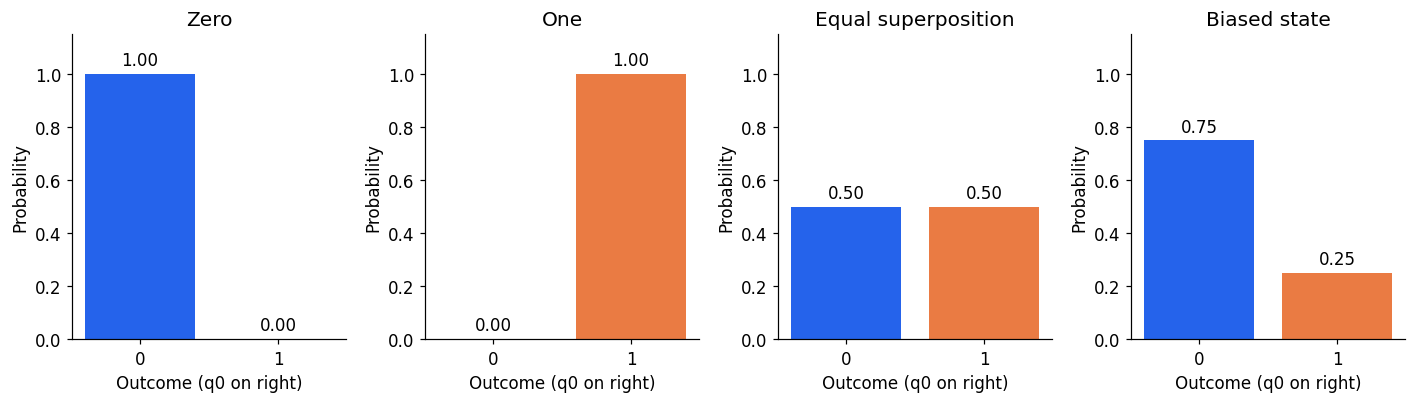

In [3]:
# Preparing four simple states with Qiskit circuits.
zero=QuantumCircuit(1)
one=QuantumCircuit(1)
one.x(0)
plus=QuantumCircuit(1)
plus.h(0)
biased=QuantumCircuit(1)
biased.initialize([np.sqrt(0.75),np.sqrt(0.25)],0)
preparations={'Zero':zero,'One':one,'Equal superposition':plus,'Biased state':biased}
fig,axes=plt.subplots(1,4,figsize=(13,3.8))
rows=[]
for ax,(name,circuit) in zip(axes,preparations.items()):
    state=exact(circuit)
    print(f'{name}: amplitudes={state.data.round(3)}, probabilities={state.probabilities().round(3)}')
    probability_plot(ax,state.probabilities(),name)
    rows.append([name,*state.probabilities()])
fig.tight_layout()
save_figure(fig,'01_qubit_probabilities','Qiskit calculates amplitudes and Born probabilities for all four preparations.')
save_table('01_qubit_probabilities',['state','P0','P1'],rows)
check('Preparing the biased state correctly',np.allclose(exact(biased).probabilities(),[0.75,0.25]))

## 3. Sampling and measuring twice

`StatevectorSampler` is a V2 primitive. It produces finite-shot samples:
1,024 independent preparations can give counts close to, but not exactly, 512/512.
Its `meas` result register is created by `measure_all()`.

For repeated measurements of the same qubit, we use Aer because the reference
StatevectorSampler does not support mid-circuit measurements. Measuring twice
without an intervening gate always gives matching classical bits. Applying reset
prepares |0⟩ even when the initial state was |1⟩.

Hadamard counts: {'0': 515, '1': 509}


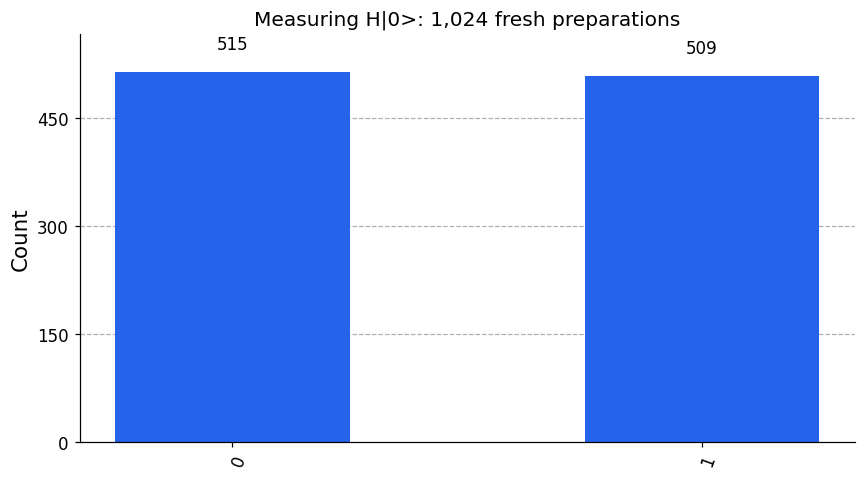

Repeated measurements, c1c0: {'00': 526, '11': 498}
After reset: {'0': 1024}


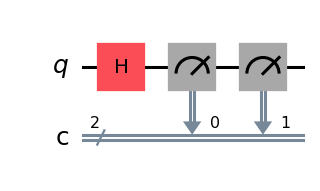

In [4]:
# Sampling the Hadamard circuit using the current V2 primitive.
counts=sample(plus)
print('Hadamard counts:',dict(sorted(counts.items())))
check('Collecting the requested number of shots',sum(counts.values())==SHOTS)
fig=plot_histogram(counts,title='Measuring H|0>: 1,024 fresh preparations',color=COLORS[0])
save_figure(fig,'02_measurement_histogram','Sampling is finite-shot; exact theoretical probabilities are 0.5 and 0.5.')
save_table('02_measurement_histogram',['outcome','count','frequency'],
           [[label,counts.get(label,0),counts.get(label,0)/SHOTS] for label in ['0','1']])

# Measuring the same qubit twice into separate classical bits.
repeated=QuantumCircuit(1,2)
repeated.h(0)
repeated.measure(0,0)
repeated.measure(0,1)
repeated_counts=aer.run(transpile(repeated,aer),shots=SHOTS,seed_simulator=SEED).result().get_counts()
print('Repeated measurements, c1c0:',dict(sorted(repeated_counts.items())))
check('Getting matching repeated measurements',set(repeated_counts)<= {'00','11'})

# Resetting a previously flipped qubit to a known state.
reset_demo=QuantumCircuit(1,1)
reset_demo.x(0)
reset_demo.reset(0)
reset_demo.measure(0,0)
reset_counts=aer.run(transpile(reset_demo,aer),shots=SHOTS,seed_simulator=SEED).result().get_counts()
print('After reset:',reset_counts)
check('Resetting to zero',reset_counts=={'0':SHOTS})
save_figure(repeated.draw('mpl'),'03_repeated_measurement_circuit','Aer simulates two measurements of one qubit; count strings display c1c0.')

## 4. Applying X, Y, Z, H, S, and T

X flips basis states. Z reverses the |1⟩ sign. Y swaps amplitudes and introduces
imaginary phases. H creates or removes superposition. S and T multiply the |1⟩
amplitude by i and exp(iπ/4). Phase can change later behavior even when current
probabilities look unchanged.

`Operator(circuit)` gives the matrix implemented by a circuit. We use it to verify
unitarity and compare gate sequences, not to replace Qiskit's circuit execution.
The heatmaps show the real and imaginary parts of the output on |+⟩.

ID on |+>: [0.707+0.j 0.707+0.j]
X on |+>: [0.707+0.j 0.707+0.j]
Y on |+>: [0.-0.707j 0.+0.707j]
Z on |+>: [ 0.707+0.j -0.707+0.j]
H on |+>: [1.+0.j 0.+0.j]
S on |+>: [0.707+0.j    0.   +0.707j]
T on |+>: [0.707+0.j  0.5  +0.5j]


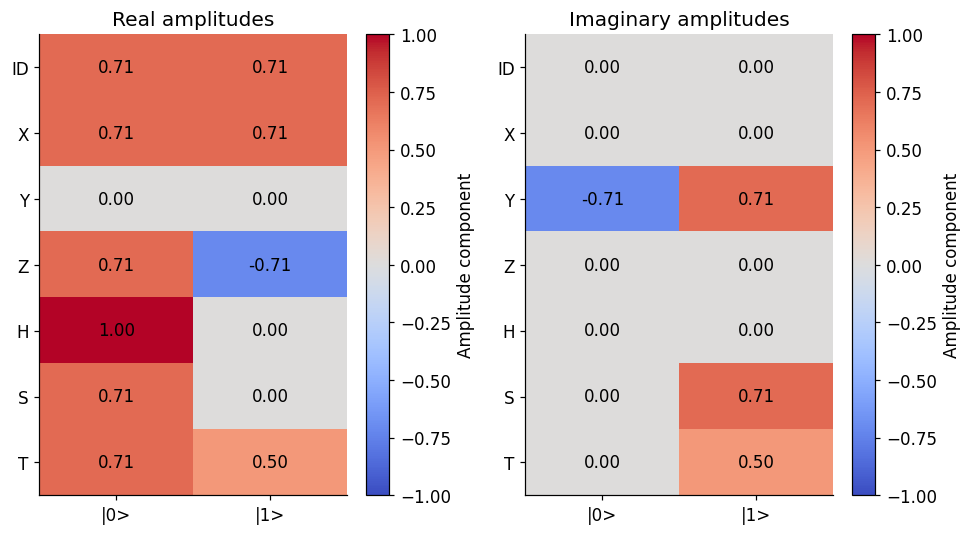

X then H: [ 0.707+0.j -0.707+0.j]
H then X: [0.707+0.j 0.707+0.j]


In [5]:
# Applying each gate through QuantumCircuit methods.
gate_names=['id','x','y','z','h','s','t']
gate_outputs=[]
for name in gate_names:
    gate=QuantumCircuit(1)
    getattr(gate,name)(0)
    check(f'Checking {name} is unitary',Operator(gate).is_unitary())
    circuit=plus.compose(gate)
    state=exact(circuit)
    gate_outputs.append(state.data)
    print(name.upper(),'on |+>:',state.data.round(3))

# Showing phase information that probability-only graphs would hide.
array=np.array(gate_outputs)
fig,axes=plt.subplots(1,2,figsize=(9,5))
for ax,values,title in zip(axes,[array.real,array.imag],['Real amplitudes','Imaginary amplitudes']):
    im=ax.imshow(values,cmap='coolwarm',vmin=-1,vmax=1,aspect='auto')
    ax.set(xticks=[0,1],xticklabels=['|0>','|1>'],yticks=range(7),
           yticklabels=[n.upper() for n in gate_names],title=title)
    for row in range(7):
        for col in range(2):ax.text(col,row,f'{values[row,col]:.2f}',ha='center',va='center')
    fig.colorbar(im,ax=ax,label='Amplitude component')
fig.tight_layout()
save_figure(fig,'04_gate_amplitudes','H maps |+> to |0>; phase gates change relative phase in different ways.')
save_table('04_gate_amplitudes',['gate','real0','imag0','real1','imag1'],
           [[name,v[0].real,v[0].imag,v[1].real,v[1].imag] for name,v in zip(gate_names,array)])

# Comparing gate orders and undoing a circuit with its inverse.
xh=QuantumCircuit(1)
xh.x(0)
xh.h(0)
hx=QuantumCircuit(1)
hx.h(0)
hx.x(0)
check('Distinguishing X then H from H then X',not exact(xh).equiv(exact(hx)))
check('Undoing a sequence with inverse()',exact(xh.compose(xh.inverse())).equiv(Statevector.from_label('0')))
print('X then H:',exact(xh).data.round(3))
print('H then X:',exact(hx).data.round(3))

## 5. Rotating and binding a circuit parameter

Rx, Ry, and Rz rotate around the Bloch sphere axes. `Parameter` lets us reuse
one circuit with different angle values. For Ry(θ)|0⟩, P(1)=sin²(θ/2).
We bind θ with `assign_parameters` before simulating.

The Bloch sphere represents pure single-qubit states up to global phase.
Its axes are expectation values of X, Y, and Z. This is a state representation,
not a picture of a tiny ball physically spinning in space.

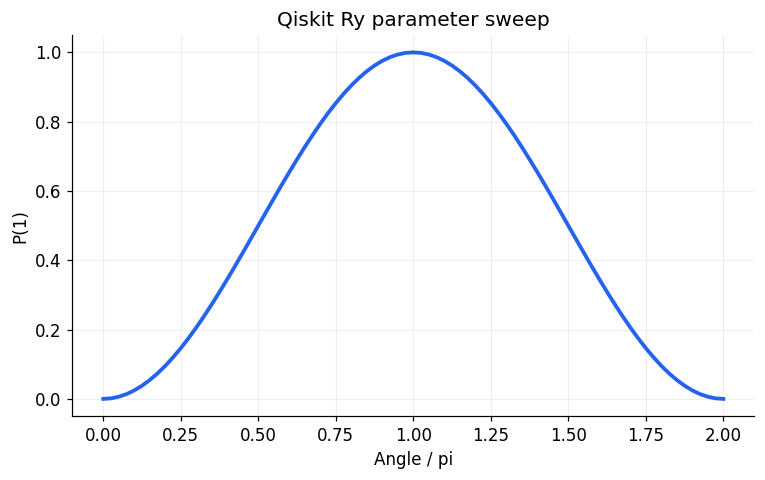

Bloch coordinates (X,Y,Z): [0.612 0.612 0.5  ]


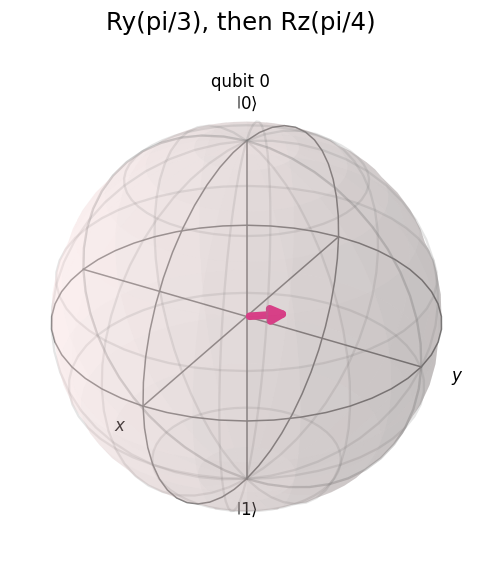

In [6]:
# Reusing one parameterized Ry circuit for an angle sweep.
angle=Parameter('theta')
rotation=QuantumCircuit(1)
rotation.ry(angle,0)
angles=np.linspace(0,2*np.pi,81)
p_one=[]
for value in angles:
    bound=rotation.assign_parameters({angle:value})
    p_one.append(exact(bound).probabilities()[1])
check('Matching the rotation formula',np.allclose(p_one,np.sin(angles/2)**2))
fig,ax=plt.subplots()
ax.plot(angles/np.pi,p_one,color=COLORS[0],linewidth=2.5)
ax.set(xlabel='Angle / pi',ylabel='P(1)',title='Qiskit Ry parameter sweep')
ax.grid(alpha=0.2)
save_figure(fig,'05_rotation_curve','Ry(0) gives zero probability of 1; Ry(pi) gives probability 1.')
save_table('05_rotation_curve',['theta_radians','P1'],zip(angles,p_one))

# Preparing a state with both a polar angle and a relative phase.
bloch_circuit=QuantumCircuit(1)
bloch_circuit.ry(np.pi/3,0)
bloch_circuit.rz(np.pi/4,0)
bloch_state=exact(bloch_circuit)
coordinates=[bloch_state.expectation_value(Pauli(axis)).real for axis in ['X','Y','Z']]
print('Bloch coordinates (X,Y,Z):',np.round(coordinates,3))
save_table('06_bloch_sphere',['X','Y','Z'],[coordinates])
save_figure(plot_bloch_multivector(bloch_state,title='Ry(pi/3), then Rz(pi/4)'),
            '06_bloch_sphere','Qiskit plots the prepared state; its Bloch vector has unit length.')
check('Keeping a pure state on the Bloch sphere',np.isclose(np.linalg.norm(coordinates),1))
rx=QuantumCircuit(1)
rx.rx(np.pi,0)
check('Flipping |0> with Rx(pi), up to global phase',exact(rx).equiv(Statevector.from_label('1')))

## 6. Revealing phase through interference

H|0⟩ is |+⟩; Z|+⟩ is |−⟩. They look identical when measured in Z,
but H before measurement distinguishes them in X. The relative sign controls
which amplitudes cancel.

Multiplying the whole state by a global phase has no observable effect. Qiskit's
`Statevector.equiv` compares states up to that global phase. A phase gate P(φ)
changes relative phase, which becomes visible after another H.

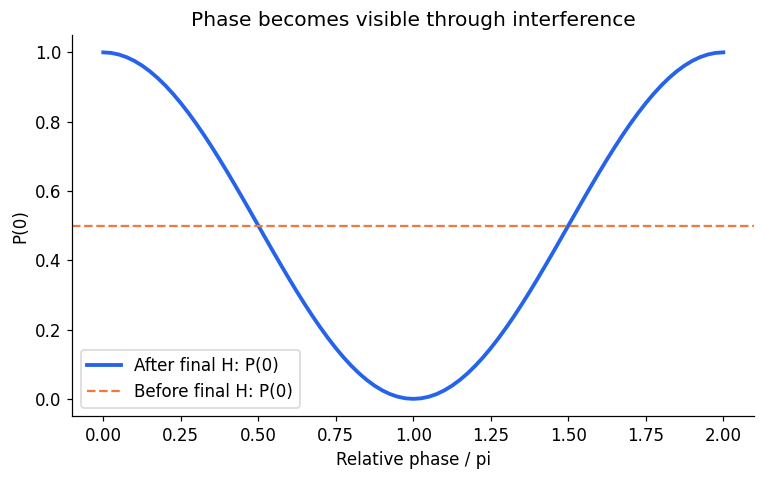

HH|0> probabilities: [1. 0.]
HZH|0> probabilities: [0. 1.]
Global phase leaves the physical state unchanged.


In [7]:
# Turning relative phase into an observable probability with H-P-H.
phases=np.linspace(0,2*np.pi,81)
interference=[]
for phi in phases:
    circuit=QuantumCircuit(1)
    circuit.h(0)
    circuit.p(phi,0)
    circuit.h(0)
    interference.append(exact(circuit).probabilities()[0])
check('Matching the interference formula',np.allclose(interference,(1+np.cos(phases))/2))
fig,ax=plt.subplots()
ax.plot(phases/np.pi,interference,label='After final H: P(0)',color=COLORS[0],linewidth=2.5)
ax.axhline(0.5,label='Before final H: P(0)',color=COLORS[1],linestyle='--')
ax.set(xlabel='Relative phase / pi',ylabel='P(0)',title='Phase becomes visible through interference')
ax.legend()
save_figure(fig,'07_phase_interference','Relative phase changes the final probability; the input Z-basis probabilities remain 50/50.')
save_table('07_phase_interference',['phase_radians','P0_after_H'],zip(phases,interference))

# Checking global phase and two useful identities.
with_global_phase=plus.copy()
with_global_phase.global_phase=0.7
check('Ignoring global phase in state equivalence',exact(with_global_phase).equiv(exact(plus)))
hh=QuantumCircuit(1)
hh.h(0)
hh.h(0)
hzh=QuantumCircuit(1)
hzh.h(0)
hzh.z(0)
hzh.h(0)
check('Recognizing HH as identity',exact(hh).equiv(Statevector.from_label('0')))
check('Recognizing HZH|0> as |1>',exact(hzh).equiv(Statevector.from_label('1')))
print('HH|0> probabilities:',exact(hh).probabilities().round(3))
print('HZH|0> probabilities:',exact(hzh).probabilities().round(3))
print('Global phase leaves the physical state unchanged.')

## 7. Reading bit order and controlled gates

With two qubits, Qiskit labels the amplitudes 00, 01, 10, 11, meaning |q1 q0⟩.
Applying X to q0 produces 01, not 10. `cx(0,1)` uses q0 as control and q1 as target.
We check the full truth table so this ordering is unambiguous.

SWAP exchanges two qubits. CCX (Toffoli) flips a target only if both controls are 1.
These gates act coherently on superpositions; controls do not imply measurement.
An n-qubit statevector has 2**n amplitudes, so classical memory grows exponentially.

X on q0 gives: {np.str_('01'): np.float64(1.0)}
CNOT: 00 -> 00
CNOT: 01 -> 11
CNOT: 10 -> 10
CNOT: 11 -> 01
SWAP result: {np.str_('10'): np.float64(1.0)}
Toffoli result: {np.str_('111'): np.float64(1.0)}


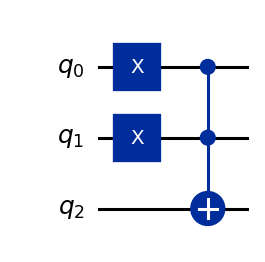

In [8]:
# Demonstrating Qiskit's rightmost-q0 string convention.
ordering=QuantumCircuit(2)
ordering.x(0)
print('X on q0 gives:',exact(ordering).probabilities_dict())
check('Putting q0 on the right in strings',np.argmax(exact(ordering).probabilities())==1)

# Checking CNOT against every computational-basis input.
cnot_rows=[]
for value in range(4):
    circuit=QuantumCircuit(2)
    if value & 1:circuit.x(0)
    if value & 2:circuit.x(1)
    circuit.cx(0,1)
    output=int(np.argmax(exact(circuit).probabilities()))
    expected=value ^ 2 if value & 1 else value
    check(f'Checking CNOT input {value:02b}',output==expected)
    cnot_rows.append([f'{value:02b}',f'{output:02b}'])
    print(f'CNOT: {value:02b} -> {output:02b}')
save_table('08_cnot_truth_table',['input_q1q0','output_q1q0'],cnot_rows)

# Swapping a basis state and exercising two controls.
swap=QuantumCircuit(2)
swap.x(0)
swap.swap(0,1)
check('Swapping 01 into 10',np.argmax(exact(swap).probabilities())==2)
toffoli=QuantumCircuit(3)
toffoli.x(0)
toffoli.x(1)
toffoli.ccx(0,1,2)
check('Flipping the Toffoli target for two active controls',exact(toffoli).equiv(Statevector.from_label('111')))
print('SWAP result:',exact(swap).probabilities_dict())
print('Toffoli result:',exact(toffoli).probabilities_dict())
save_figure(toffoli.draw('mpl'),'08_toffoli_circuit','Starting from 011, CCX with controls q0 and q1 produces 111 (q2q1q0).')

## 8. Creating a Bell pair and a GHZ state

Apply H to q0 and CNOT from q0 to q1. The Bell state is (|00⟩+|11⟩)/√2.
Each individual qubit is maximally mixed; `partial_trace` discards the other qubit
to reveal that reduced state. Its purity is 0.5, even though the full Bell state
is pure. This is one signature of entanglement for a bipartite pure state.

A classical mixture of 00 and 11 has the same Z-basis statistics. Compare X-basis
measurements to distinguish these two preparations. A GHZ circuit extends this
pattern to three qubits, producing (|000⟩+|111⟩)/√2. Neither entanglement nor
correlation lets us send messages faster than light.

Bell counts: {'00': 515, '11': 509}
Reduced state of q0:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
Reduced-state purity: 0.4999999999999998


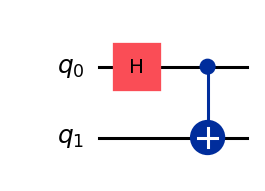

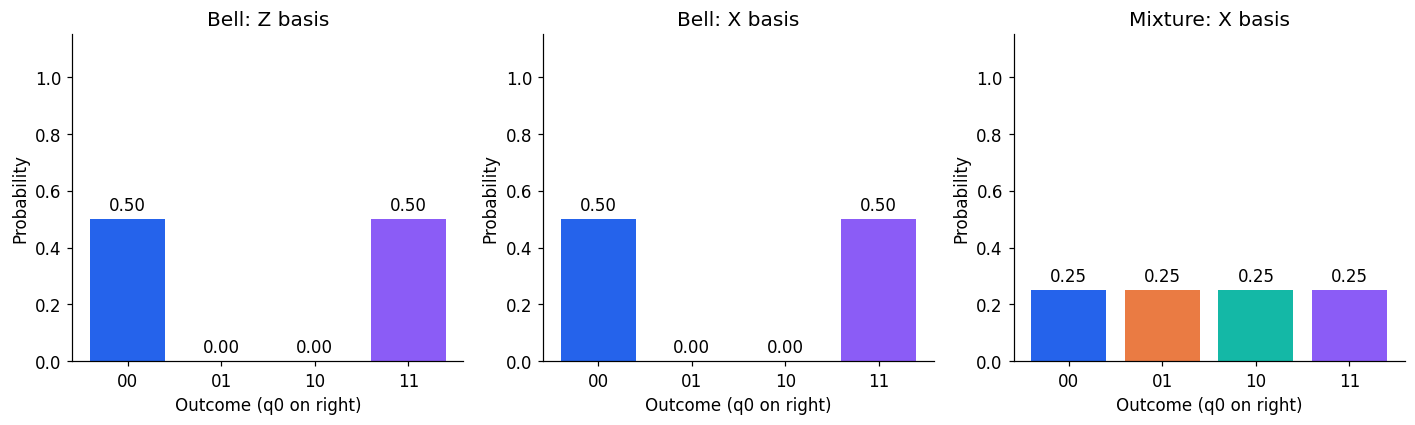

GHZ counts: {'000': 515, '111': 509}


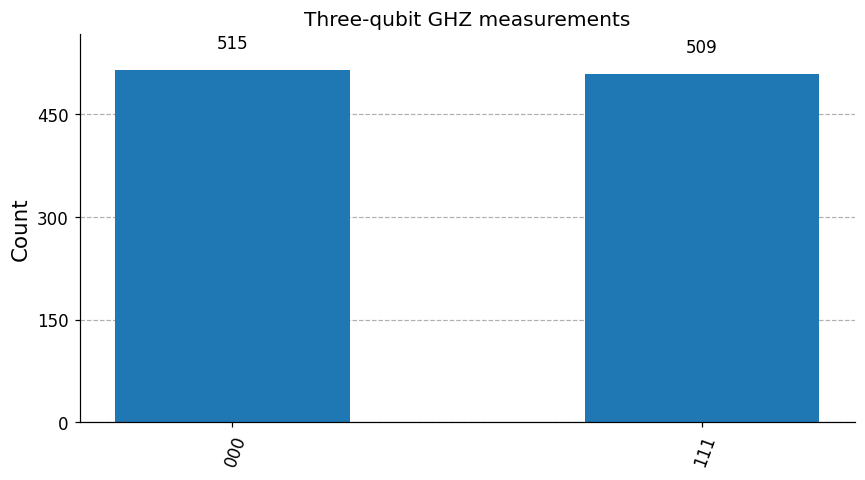

In [9]:
# Preparing a Bell pair using the standard two-gate circuit.
bell=QuantumCircuit(2)
bell.h(0)
bell.cx(0,1)
bell_state=exact(bell)
bell_counts=sample(bell)
print('Bell counts:',dict(sorted(bell_counts.items())))
check('Allowing only Bell outcomes 00 and 11',set(bell_counts)<= {'00','11'})
reduced=partial_trace(bell_state,[1])
print('Reduced state of q0:\n',reduced.data.round(3))
print('Reduced-state purity:',float(purity(reduced).real))
check('Finding a maximally mixed reduced state',np.allclose(reduced.data,np.eye(2)/2))
save_figure(bell.draw('mpl'),'09_bell_circuit','Qiskit draws q0 on the top wire; H then CX prepares the Bell state.')

# Comparing coherent and incoherent preparations in a second measurement basis.
change_basis=QuantumCircuit(2)
change_basis.h([0,1])
bell_x=bell_state.evolve(change_basis).probabilities()
mixture=DensityMatrix(np.diag([0.5,0,0,0.5]))
mixture_x=mixture.evolve(change_basis).probabilities()
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,p,title in zip(axes,[bell_state.probabilities(),bell_x,mixture_x],
                       ['Bell: Z basis','Bell: X basis','Mixture: X basis']):
    probability_plot(ax,p,title)
fig.tight_layout()
save_figure(fig,'10_entanglement_comparison','For these two preparations, X-basis results reveal Bell coherence that Z-basis counts alone cannot establish.')
save_table('10_entanglement_comparison',['outcome','bell_Z','bell_X','mixture_X'],
           [[f'{i:02b}',bell_state.probabilities()[i],bell_x[i],mixture_x[i]] for i in range(4)])
check('Keeping Bell correlations in X',np.allclose(bell_x,[0.5,0,0,0.5]))
check('Getting uniform mixture outcomes in X',np.allclose(mixture_x,[0.25]*4))

# Extending the entangled state to three qubits.
ghz=QuantumCircuit(3)
ghz.h(0)
ghz.cx(0,1)
ghz.cx(1,2)
ghz_counts=sample(ghz)
print('GHZ counts:',dict(sorted(ghz_counts.items())))
check('Allowing only GHZ outcomes 000 and 111',set(ghz_counts)<= {'000','111'})
save_figure(plot_histogram(ghz_counts,title='Three-qubit GHZ measurements'),'11_ghz_histogram',
            'The ideal GHZ circuit produces only 000 and 111; finite counts fluctuate.')
save_table('11_ghz_histogram',['outcome','count'],sorted(ghz_counts.items()))

## 9. Solving Deutsch’s problem with circuit oracles

f maps one bit to one bit. Constant functions have equal outputs; balanced
functions have different outputs. The oracle maps |x,y⟩ to |x,y XOR f(x)⟩,
where x is q0 and y is q1. Qiskit displays the state as |y x⟩.

Prepare q0 in |+⟩ and q1 in |−⟩, apply one oracle, then H on q0.
q0=0 means constant; q0=1 means balanced. The oracle's flip becomes a relative
sign on |−⟩: phase kickback. The one-query advantage assumes access to a black-box
oracle; our circuit construction explicitly knows each toy truth table.

constant zero : q0 probabilities = [1. 0.]
constant one : q0 probabilities = [1. 0.]
identity : q0 probabilities = [0. 1.]
opposite : q0 probabilities = [0. 1.]


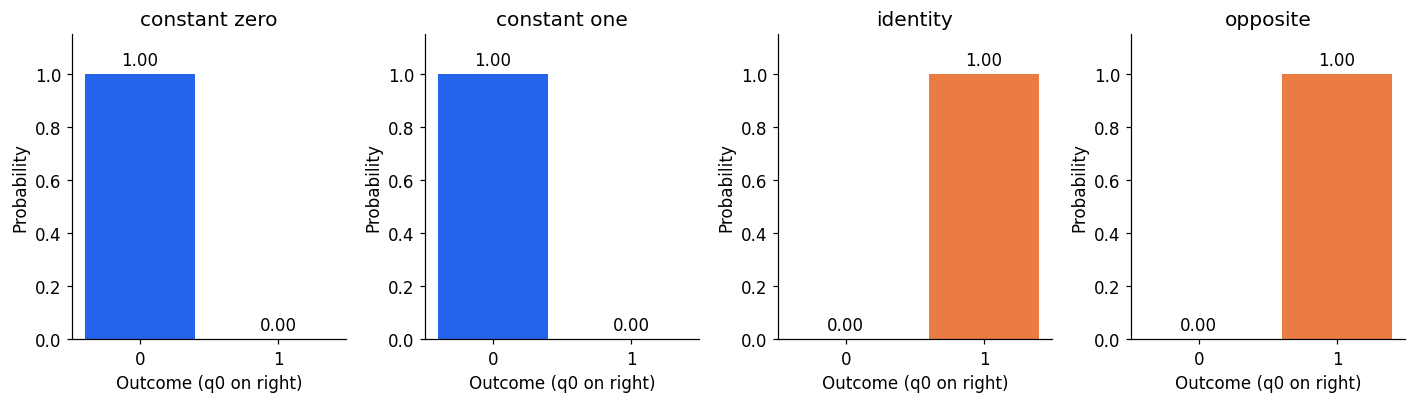

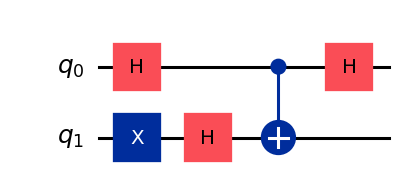

In [10]:
# Implementing all four one-bit oracles using Qiskit gates.
def deutsch_circuit(kind):
    circuit=QuantumCircuit(2)
    circuit.x(1)
    circuit.h([0,1])
    if kind=='constant one':
        circuit.x(1)
    elif kind=='identity':
        circuit.cx(0,1)
    elif kind=='opposite':
        circuit.cx(0,1)
        circuit.x(1)
    elif kind!='constant zero':
        raise ValueError('Choose one of the four demonstrated functions.')
    circuit.h(0)
    return circuit

# Reading only q0's marginal probabilities, not the whole two-qubit state.
kinds=['constant zero','constant one','identity','opposite']
fig,axes=plt.subplots(1,4,figsize=(13,3.8))
deutsch_rows=[]
for ax,kind in zip(axes,kinds):
    circuit=deutsch_circuit(kind)
    p=exact(circuit).probabilities(qargs=[0])
    expected=0 if kind.startswith('constant') else 1
    check(f'Classifying {kind}',np.isclose(p[expected],1))
    print(kind,': q0 probabilities =',p.round(3))
    probability_plot(ax,p,kind)
    deutsch_rows.append([kind,*p])
fig.tight_layout()
save_figure(fig,'12_deutsch_results','Both constant functions give q0=0; both balanced functions give q0=1 with certainty in the ideal circuit.')
save_table('12_deutsch_results',['function','P0','P1'],deutsch_rows)
save_figure(deutsch_circuit('identity').draw('mpl'),'13_deutsch_circuit',
            'The identity oracle is CX(q0,q1); the auxiliary q1 begins in |->.')

## 10. Searching four labels with Grover’s algorithm

Our labels are 00, 01, 10, 11 in q1q0 order. The oracle uses X gates around
CZ to change the sign of exactly one marked basis state. The diffuser uses H, X,
CZ, X, H. This diffuser equals the usual reflection up to an irrelevant global sign.

For one marked item among four, one iteration succeeds with probability 1.
An extra iteration overshoots. Specifying a target here is how we build a toy
recognition oracle; this is not a search of a real database.

0 iterations: [0.25 0.25 0.25 0.25]
1 iterations: [0. 0. 1. 0.]
2 iterations: [0.25 0.25 0.25 0.25]


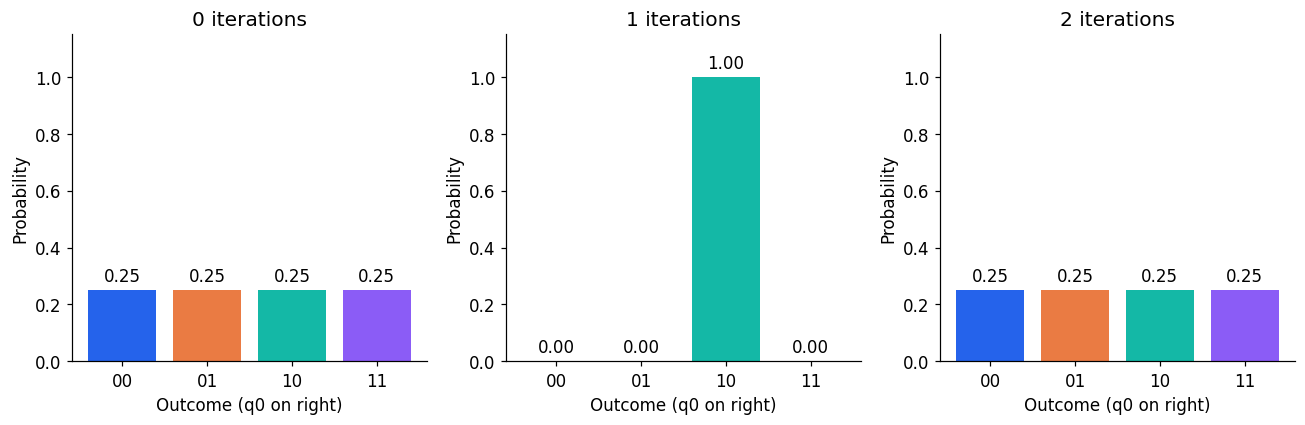

Grover target 10 counts: {'10': 1024}


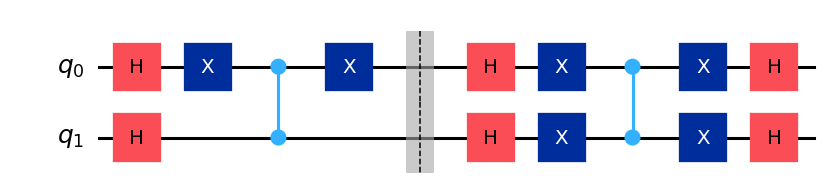

In [11]:
# Building a phase oracle with gates instead of manually editing amplitudes.
def grover_circuit(target=2,iterations=1):
    if target not in range(4):
        raise ValueError('Choose target 0, 1, 2, or 3.')
    circuit=QuantumCircuit(2)
    circuit.h([0,1])
    for _ in range(iterations):
        for qubit in range(2):
            if not (target >> qubit) & 1:circuit.x(qubit)
        circuit.cz(0,1)
        for qubit in range(2):
            if not (target >> qubit) & 1:circuit.x(qubit)
        circuit.barrier()
        circuit.h([0,1])
        circuit.x([0,1])
        circuit.cz(0,1)
        circuit.x([0,1])
        circuit.h([0,1])
    return circuit

# Comparing the initial distribution with one and two iterations.
fig,axes=plt.subplots(1,3,figsize=(12,4))
grover_rows=[]
for ax,iterations in zip(axes,[0,1,2]):
    p=exact(grover_circuit(2,iterations)).probabilities()
    print(f'{iterations} iterations:',p.round(3))
    probability_plot(ax,p,f'{iterations} iterations')
    grover_rows.append(p)
fig.tight_layout()
save_figure(fig,'14_grover_results','One iteration concentrates probability on 10; two return to a uniform distribution in this four-item example.')
save_table('14_grover_results',['outcome','initial','one_iteration','two_iterations'],
           [[f'{i:02b}',*[row[i] for row in grover_rows]] for i in range(4)])
for target in range(4):
    check(f'Finding Grover target {target:02b}',np.isclose(exact(grover_circuit(target)).probabilities()[target],1))
check('Overshooting after two Grover iterations',np.allclose(grover_rows[2],[0.25]*4))
print('Grover target 10 counts:',sample(grover_circuit(2)))
save_figure(grover_circuit(2).draw('mpl',fold=-1),'15_grover_circuit',
            'The left block marks 10; the right block amplifies it through interference.')

## 11. Teleporting with actual measurements and classical control

Alice holds the input q0 and half of a Bell pair q1; Bob holds q2.
Alice applies CX(q0,q1), H(q0), then measures q0 into c0 and q1 into c1.
Bob applies X if c1=1, followed by Z if c0=1. We use Qiskit's `if_test` blocks
and Aer to execute these dynamic operations.

Aer saves Bob's reduced density matrix separately for each observed classical
branch. We compare it with the original input using `state_fidelity`, including
phase information. Classical messages are displayed c1c0 (b a).

All four branches are checked, and we repeat the experiment for six input states.
Teleportation consumes Alice's input; it neither clones it nor sends information
faster than light. Saved simulator states are a debugging capability, not something
hardware measurements directly reveal.

complex input: c1c0=00, count=239, fidelity=1.000000
complex input: c1c0=01, count=254, fidelity=1.000000
complex input: c1c0=10, count=278, fidelity=1.000000
complex input: c1c0=11, count=253, fidelity=1.000000
All six input states passed all four branch-fidelity checks.


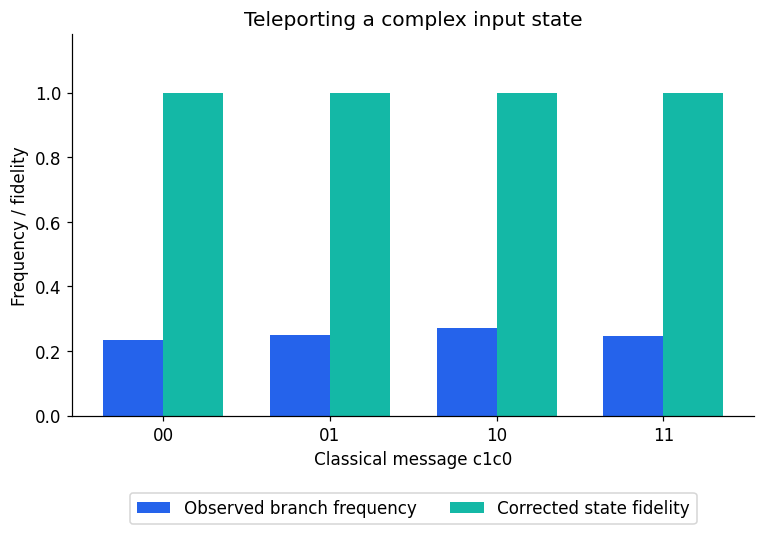

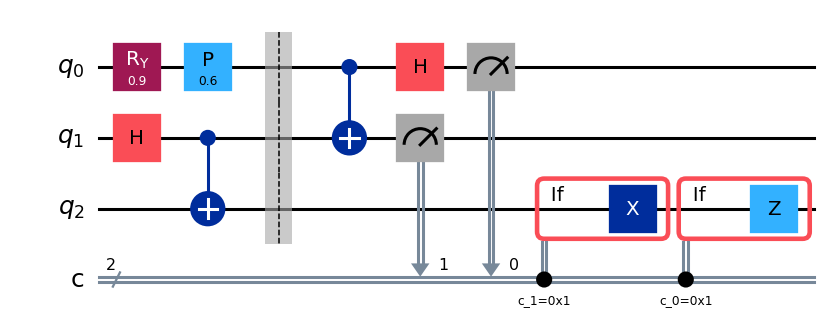

In [12]:
# Preparing arbitrary input states with a reversible one-qubit circuit.
def prepare_input(theta,phi):
    circuit=QuantumCircuit(1)
    circuit.ry(theta,0)
    circuit.p(phi,0)
    return circuit

# Implementing the full protocol with mid-circuit measurements and if_test.
def teleport_circuit(preparation):
    circuit=QuantumCircuit(3,2)
    circuit.compose(preparation,[0],inplace=True)
    circuit.h(1)
    circuit.cx(1,2)
    circuit.barrier()
    circuit.cx(0,1)
    circuit.h(0)
    circuit.measure(0,0)
    circuit.measure(1,1)
    with circuit.if_test((circuit.clbits[1],1)):
        circuit.x(2)
    with circuit.if_test((circuit.clbits[0],1)):
        circuit.z(2)
    return circuit

# Checking each classical branch using a conditional reduced-state save.
def test_teleportation(preparation,label):
    circuit=teleport_circuit(preparation)
    circuit.save_density_matrix([2],label='bob',conditional=True)
    result=aer.run(transpile(circuit,aer),shots=SHOTS,seed_simulator=SEED).result()
    branch_states=result.data(0)['bob']
    counts=result.get_counts()
    check(f'Observing all branches for {label}',len(branch_states)==4)
    expected=Statevector.from_instruction(preparation)
    rows=[]
    for key,bob in sorted(branch_states.items()):
        bits=format(int(key,16),'02b')
        fidelity=float(state_fidelity(expected,bob))
        check(f'Teleporting {label} in branch {bits}',np.isclose(fidelity,1))
        rows.append([label,bits,counts.get(bits,0),fidelity])
    return rows
input_prep=prepare_input(0.9,0.6)
teleport_rows=test_teleportation(input_prep,'complex input')
for row in teleport_rows:print(f'{row[0]}: c1c0={row[1]}, count={row[2]}, fidelity={row[3]:.6f}')

# Testing basis states and states with real and imaginary relative phases.
for label,theta,phi in [('zero',0,0),('one',np.pi,0),('plus',np.pi/2,0),
                        ('minus',np.pi/2,np.pi),('plus i',np.pi/2,np.pi/2)]:
    extra=test_teleportation(prepare_input(theta,phi),label)
    teleport_rows.extend(extra)
print('All six input states passed all four branch-fidelity checks.')
save_table('16_teleportation_results',['input','classical_c1c0','shots','fidelity'],teleport_rows)
fig,ax=plt.subplots()
x=np.arange(4)
ax.bar(x-0.18,[row[2]/SHOTS for row in teleport_rows[:4]],0.36,label='Observed branch frequency',color=COLORS[0])
ax.bar(x+0.18,[row[3] for row in teleport_rows[:4]],0.36,label='Corrected state fidelity',color=COLORS[2])
ax.set(xticks=x,xticklabels=[row[1] for row in teleport_rows[:4]],ylim=(0,1.18),
       xlabel='Classical message c1c0',ylabel='Frequency / fidelity',title='Teleporting a complex input state')
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2)
save_figure(fig,'16_teleportation_results','All four corrected branches have fidelity 1; their sampled frequencies are near 0.25.')
save_figure(teleport_circuit(input_prep).draw('mpl',fold=-1),'17_teleportation_circuit',
            'Qiskit if_test blocks execute X conditioned on c1, then Z conditioned on c0.')

## 12. Exploring density matrices and a bit-flip channel

A density matrix describes pure states and statistical mixtures.
Its diagonal gives measurement probabilities. Off-diagonal entries describe coherence
in that basis. Purity Tr(ρ²) is 1 for a pure state and smaller for a mixture.

We build an Aer `pauli_error`: apply X with probability p and I with probability 1−p.
Its channel is (1−p)ρ+pXρX†. Starting from |0⟩, the probabilities are (1−p,p).
At p=1 the flip is deterministic and the state becomes pure again.

An explicit error instruction keeps the noise location unambiguous. This is a toy
noise channel, not a calibrated hardware model. Real devices have additional
relaxation, phase, gate, and readout errors.

Noisy density matrix:
 [[0.8+0.j 0. +0.j]
 [0. +0.j 0.2+0.j]]
Probabilities: [0.8 0.2]
Purity: 0.6800000000000002


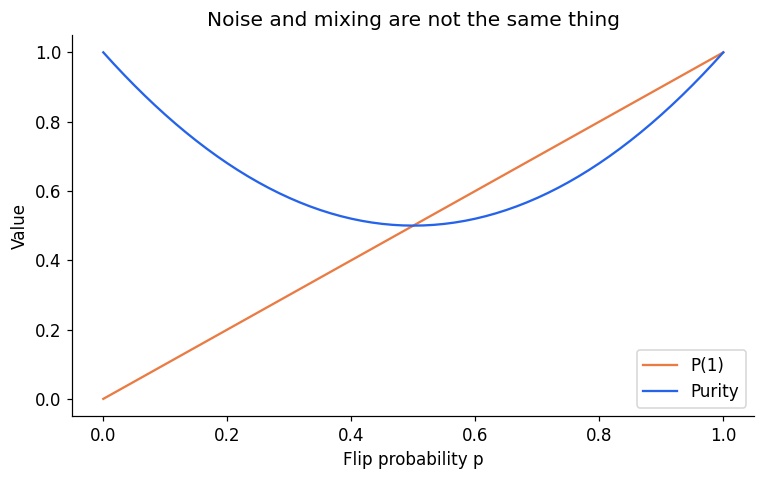

Noisy counts (4096 shots): {'0': 3307, '1': 789}


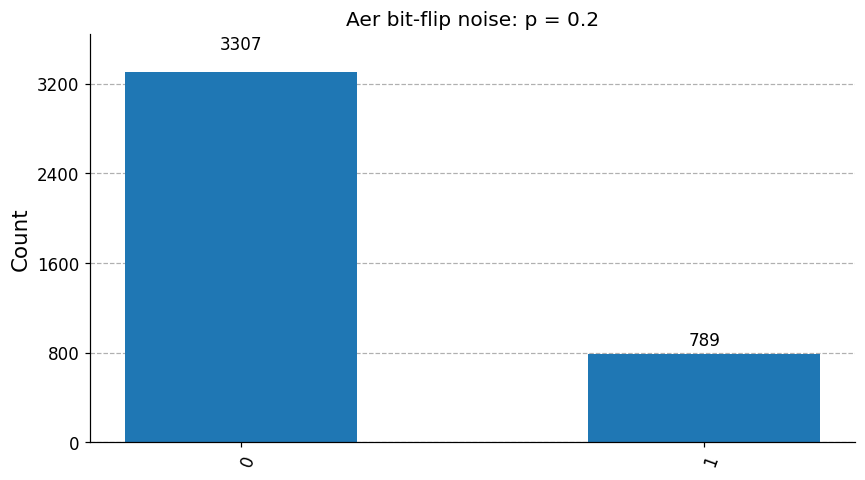

Superposition after H : [1. 0.]
Mixture after H : [0.5 0.5]


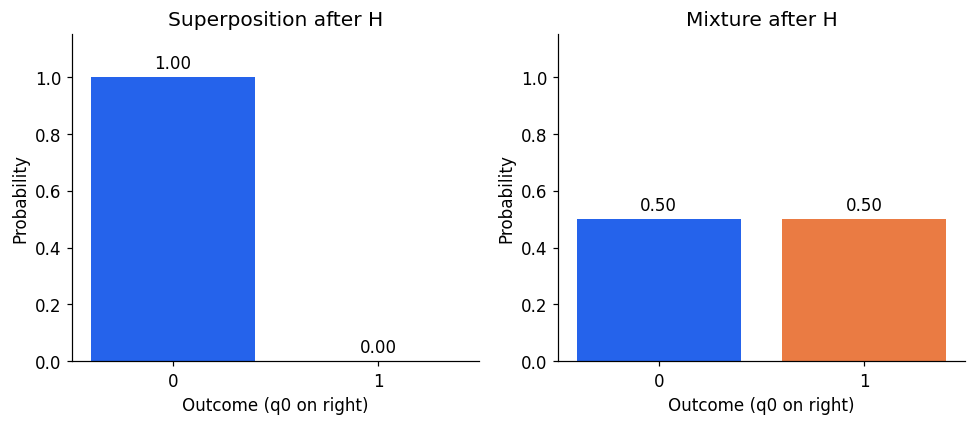

In [13]:
# Creating and simulating an explicit Aer error channel.
error=pauli_error([('X',0.2),('I',0.8)])
noisy=QuantumCircuit(1)
noisy.append(error.to_instruction(),[0])
noisy.save_density_matrix(label='rho')
rho=aer.run(noisy,shots=1,seed_simulator=SEED).result().data(0)['rho']
print('Noisy density matrix:\n',rho.data.round(3))
print('Probabilities:',rho.probabilities().round(3))
print('Purity:',float(purity(rho).real))
check('Getting the noisy probabilities',np.allclose(rho.probabilities(),[0.8,0.2]))
check('Getting the expected purity',np.isclose(purity(rho),0.68))
check('Keeping the density matrix valid',rho.is_valid())

# Sweeping the same Qiskit channel through DensityMatrix.evolve.
noise_values=np.linspace(0,1,61)
noise_rows=[]
for p in noise_values:
    channel=pauli_error([('X',float(p)),('I',float(1-p))]).to_quantumchannel()
    state=DensityMatrix.from_label('0').evolve(channel)
    noise_rows.append([p,state.probabilities()[1],float(purity(state).real)])
fig,ax=plt.subplots()
ax.plot(noise_values,[row[1] for row in noise_rows],label='P(1)',color=COLORS[1])
ax.plot(noise_values,[row[2] for row in noise_rows],label='Purity',color=COLORS[0])
ax.set(xlabel='Flip probability p',ylabel='Value',title='Noise and mixing are not the same thing')
ax.legend()
save_figure(fig,'18_noise_and_purity','Mixing is strongest at p=0.5. A certain flip at p=1 returns to a pure state.')
save_table('18_noise_and_purity',['flip_probability','P1','purity'],noise_rows)

# Sampling the noisy circuit to compare ideal probabilities with finite shots.
noisy_measured=QuantumCircuit(1,1)
noisy_measured.append(error.to_instruction(),[0])
noisy_measured.measure(0,0)
noisy_counts=aer.run(noisy_measured,shots=4096,seed_simulator=SEED).result().get_counts()
print('Noisy counts (4096 shots):',dict(sorted(noisy_counts.items())))
check('Checking a broad noise sampling tolerance',abs(noisy_counts.get('1',0)/4096-0.2)<0.05)
save_figure(plot_histogram(noisy_counts,title='Aer bit-flip noise: p = 0.2'),'19_noise_histogram',
            'Sampled frequencies approach 0.8 for 0 and 0.2 for 1; they are not exact probabilities.')
save_table('19_noise_histogram',['outcome','count'],sorted(noisy_counts.items()))

# Comparing coherence with a classical 50/50 mixture.
coherent=DensityMatrix(Statevector.from_instruction(plus))
mixed=DensityMatrix(np.eye(2)/2)
fig,axes=plt.subplots(1,2,figsize=(9,4))
coherence_rows=[]
for ax,name,state in zip(axes,['Superposition after H','Mixture after H'],[coherent,mixed]):
    p=state.evolve(plus).probabilities()
    probability_plot(ax,p,name)
    coherence_rows.append([name,*p])
    print(name,':',p.round(3))
fig.tight_layout()
save_figure(fig,'20_coherence_comparison','H maps |+> to |0>, while the maximally mixed state remains 50/50.')
save_table('20_coherence_comparison',['input','P0_after_H','P1_after_H'],coherence_rows)
check('Leaving |+> unchanged by bit-flip noise',np.isclose(state_fidelity(coherent,coherent.evolve(error.to_quantumchannel())),1))

## 13. Compiling a circuit without changing its meaning

`transpile` rewrites a circuit to supported gates and can optimize it.
Here we compile a Bell circuit into the basis {rz, sx, x, cx}; this is an example
basis, not a claim about a particular hardware device. Circuit depth counts
layers of operations, and `count_ops` counts instructions.

Different versions and targets may produce different valid compilations.
We verify the resulting operation is equivalent up to global phase.

Original operations: {'h': 1, 'cx': 1} depth: 2
Compiled operations: {'rz': 2, 'sx': 1, 'cx': 1} depth: 4


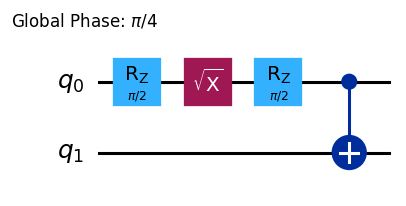

In [14]:
# Compiling to an explicit basis and comparing the resulting operators.
compiled=transpile(bell,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=SEED)
print('Original operations:',dict(bell.count_ops()),'depth:',bell.depth())
print('Compiled operations:',dict(compiled.count_ops()),'depth:',compiled.depth())
check('Preserving the Bell circuit under compilation',Operator(bell).equiv(Operator(compiled)))
check('Using only the selected basis',set(compiled.count_ops()) <= {'rz','sx','x','cx'})
save_figure(compiled.draw('mpl',fold=-1),'21_transpiled_circuit','The compiled circuit implements the same Bell preparation with the selected gate basis.')

## 14. Trying six small exercises

Predict first, then make a new code cell for your answer.

1. Prepare P(0)=0.2 and P(1)=0.8 with `initialize`.
2. Undo Ry(π/2) using a second rotation.
3. Compare X→H with H→X in the X measurement basis.
4. Flip q1 in a Bell pair. Which outcomes remain?
5. Change the Grover target to each of the four possible labels.
6. Prepare |+i⟩ with H then S. What are its X, Y, and Z expectations?

**Solutions follow. Pause here to try independently.**

In [15]:
# Preparing the requested unequal probabilities.
answer=QuantumCircuit(1)
answer.initialize(np.sqrt([0.2,0.8]),0)
check('Solving exercise 1',np.allclose(exact(answer).probabilities(),[0.2,0.8]))
print('1. Probabilities:',exact(answer).probabilities().round(3))

# Undoing the rotation by negating its angle.
answer=QuantumCircuit(1)
answer.ry(np.pi/2,0)
answer.ry(-np.pi/2,0)
check('Solving exercise 2',exact(answer).equiv(Statevector.from_label('0')))
print('2. Inverse rotation returns |0>.')

# Measuring the differently ordered circuits in the X basis.
measure_x=QuantumCircuit(1)
measure_x.h(0)
p_xh=exact(xh.compose(measure_x)).probabilities()
p_hx=exact(hx.compose(measure_x)).probabilities()
check('Solving exercise 3',np.allclose(p_xh,[0,1]) and np.allclose(p_hx,[1,0]))
print('3. X-basis probabilities:',p_xh.round(3),p_hx.round(3))

# Flipping q1 after creating the Bell pair.
answer=bell.copy()
answer.x(1)
check('Solving exercise 4',np.allclose(exact(answer).probabilities(),[0,0.5,0.5,0]))
print('4. The outcomes are 01 and 10.')

# Verifying every Grover target instead of relying on one example.
for target in range(4):
    check(f'Solving exercise 5 for {target:02b}',sample(grover_circuit(target))=={format(target,'02b'):SHOTS})
print('5. Every marked target is measured with certainty after one iteration.')

# Preparing a state on the positive Y axis and inspecting its expectations.
answer=QuantumCircuit(1)
answer.h(0)
answer.s(0)
state=exact(answer)
xyz=[state.expectation_value(Pauli(axis)).real for axis in ['X','Y','Z']]
check('Solving exercise 6',np.allclose(xyz,[0,1,0]))
print('6. X, Y, Z expectations:',np.round(xyz,3))

1. Probabilities: [0.2 0.8]
2. Inverse rotation returns |0>.
3. X-basis probabilities: [0. 1.] [1. 0.]
4. The outcomes are 01 and 10.
5. Every marked target is measured with certainty after one iteration.
6. X, Y, Z expectations: [0. 1. 0.]


## 15. Saving your results

The final cell writes the actual environment, passed checks, graph captions,
and CSV files into a results archive. In Colab, download that ZIP from the Files
sidebar; save the executed notebook separately with File → Download → .ipynb.
Colab runtime files are temporary.

If you change an example and a check fails, compare your new goal with the original
expected result. If you see `NameError`, rerun from the beginning. A missing package
usually means the installation cell has not finished or the runtime needs a fresh start.

In [16]:
# Recording the checks and figures generated by this execution.
(RESULTS/'checks.json').write_text(json.dumps({'passed':len(checks),'checks':checks},indent=2))
(RESULTS/'figures.json').write_text(json.dumps(figures,indent=2))
print(f'Passed {len(checks)} checks; created {len(figures)} figures.')
print('Author: Swayam Shakya')
print('Quantum framework: Qiskit + Qiskit Aer')

# Archiving the reproducible outputs for download from Colab's Files sidebar.
from zipfile import ZipFile, ZIP_DEFLATED
with ZipFile('qiskit_generated_results.zip','w',ZIP_DEFLATED) as archive:
    for directory in [ASSETS,RESULTS]:
        for path in sorted(directory.glob('*')):
            if path.is_file():archive.write(path,arcname=str(path))
print('Created qiskit_generated_results.zip')

Passed 303 checks; created 21 figures.
Author: Swayam Shakya
Quantum framework: Qiskit + Qiskit Aer
Created qiskit_generated_results.zip


## References

- [Qiskit bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering)
- [StatevectorSampler](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler)
- [Qiskit Aer simulator tutorials](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html)
- [Aer noise models](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html)
- [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)

**By Swayam Shakya.**